# Step 4b-3 · Automatic digitization: **Qwen3-VL-4B reads, pixels measure**

**Inputs (choose in SETTINGS):**
* `"rebuilt"` — the 12 plots rebuilt in `02_real_plots_multimodel` (6 line / scatter, 4 bar, 2 pie), exact ground truth;
* `"gallery"` — the synthetic gallery in `gallery/` (made by `gallery/make_gallery.py`): **heatmaps, contour / colour maps (2-D surfaces), histograms, box plots, polar plots, stacked and horizontal bars, 3-D bars, 3-D scatter, 3-D surfaces**, several styles each, exact ground truth — plus **10 unsupported plots** (violin, radar, network, Venn, micrograph, ternary, table, multi-panel, dendrogram, schematic) that must be **rejected**;
* any folder of images (CSV + recreated plot, no score).

**Only the VLM describes the plots** — nothing about any figure is typed by hand.

1. **VLM reads text** (Qwen3-VL-4B, local). Question 1: chart type (14 supported types or "other"), axis titles and tick labels. Question 2 depends on the type (series / bar layout / pie slices / histogram series / box categories / heatmap rows, columns and colour bar / polar angle and radius labels / 3-D axes, colour bar, stems).
2. **Pixel check** — tick-label counts, right axis, broken axis (red-box re-ask per piece), y-title re-read.
3. **Digitize** by chart type (one module each, no per-figure settings): `extract.py` line/scatter · `bars.py` vertical bars · `stacked.py` stacked + horizontal bars · `pie.py` · `hist.py` · `boxplot.py` · `heatmap.py` heatmaps + contour maps (colour scale from `colorbar.py`) · `polar.py` · `axes3d.py` 3-D camera (axis lines + ticks → projective camera) + `plot3d.py` 3-D bars / scatter / surfaces.
4. **Rejection gates** (`reject.py`) — every image ends as **ok** (scored), **flagged** (extracted, but part is a guess, e.g. 3-D depth without a cue — not scored) or **rejected** (not extracted: unsupported type, several panels, or a failed self-check such as tick-label fit, labels paired, boxes found, colour-scale distance, camera reprojection). Rejected / flagged images never enter the accuracy mean, and the reason is printed.
5. **Recreate** the plot from the extracted data, and **score** it against the ground truth.

VLM answers are cached per image (`<out_dir>/<figure>/vlm_spec.json`); answers from older prompts are re-asked automatically; when only the pixel checks changed, the cached answers are re-checked (only follow-up questions are asked).

In [1]:
# ============================ SETTINGS (everything configurable is here) ============================
CONFIG = {
    "bench_dir": "../02_real_plots_multimodel",   # rebuilt plots + ground truth + leaderboard come from here
    "images": "rebuilt",                     # "rebuilt": the 12 rebuilt plots of notebook 02 (scored)
                                             # "gallery": the synthetic gallery of new chart types + unsupported plots (scored)
                                             # or a folder path, e.g. "../data": any plots (CSV + recreated plot, no score)
    "gallery_dir": "gallery",                # images/, truth/, specs/ (specs = what an ideal VLM would read: dry run only)
    "out_dir": "outputs_qwen",               # one folder per VLM run (older Qwen runs: outputs_v2, outputs_v3; OpenAI: outputs_openai)

    "spec_source": "qwen",                   # "qwen": local Qwen3-VL (free) | "openai": OpenAI API (paid)
                                             # "files": spec files instead of a VLM (dry run): manual_specs/, or gallery/specs/ for the gallery
    # --- Qwen (local, runs on the Mac - no cost)
    "qwen_model": "Qwen/Qwen3-VL-4B-Instruct",
    "max_new_tokens": 1024,
    # --- OpenAI (paid) - switched off; to use it set spec_source = "openai" and uncomment these
    # "openai_model": "gpt-6-astra",         # most capable OpenAI model with image input; cheaper: "gpt-6.1-sol"
    # "openai_detail": "high",               # "high" | "original" | "auto"
    # "openai_reasoning": "medium",          # "low" | "medium" | "high"
    "upscale_below": 1000,                   # images smaller than this are enlarged for the VLM only (small labels read better)
    "use_cache": True,                       # reuse saved VLM answers. False: ask again
    "pixel_check": True,                     # cross-check the VLM answer with the pixels and re-ask where they disagree

    "hit_threshold": 5.0,                    # % of the y-axis span
}
# To FIX a VLM mistake for one image: edit "spec" in <out_dir>/<figure>/vlm_spec.json and re-run (use_cache=True).

In [2]:
import json, time, sys, warnings
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image as IPImage
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 250)

sys.path.insert(0, ".")
import autodig
from autodig import QwenSpecReader, OpenAISpecReader, FileSpecReader, pipeline, recreate, read_spec, side_by_side, evaluate as E, report as RP
from autodig.run import _jsonable

BENCH, OUT = Path(CONFIG["bench_dir"]), Path(CONFIG["out_dir"])
OUT.mkdir(exist_ok=True)
MODE = CONFIG["images"] if CONFIG["images"] in ("rebuilt", "gallery") else "folder"
SCORED = MODE == "rebuilt"
GAL = Path(CONFIG["gallery_dir"])
if not (GAL / "images").exists() and Path("gallery.zip").exists():      # first run: unpack the gallery
    import zipfile
    zipfile.ZipFile("gallery.zip").extractall(".")
    print("unpacked gallery.zip ->", GAL)
if MODE == "gallery":
    from autodig import gallery_eval as GE
    IMAGES = {p.stem: p for p in sorted((GAL / "images").glob("*.png"))}
    GT = {n: json.loads((GAL / "truth" / f"{n}.json").read_text()) for n in IMAGES}
elif SCORED:
    FIGURES, score_figure = RP.load_chartbench(BENCH)
    import chartbench.config as cbcfg
    cbcfg.CONFIG["scoring"]["hit_threshold"] = CONFIG["hit_threshold"]
    IMAGES = {fid: BENCH / "outputs" / "rebuilt_plots" / f"{fid}_rebuilt.png" for fid in FIGURES}
    GT = {fid: json.loads((BENCH / "outputs" / "ground_truth" / f"{fid}.json").read_text()) for fid in FIGURES}
if MODE == "folder":
    folder = Path(CONFIG["images"])
    IMAGES = {p.stem[:40]: p for p in sorted(folder.iterdir()) if p.suffix.lower() in (".png", ".jpg", ".jpeg")}
for n, p in IMAGES.items():
    print(f"{n:20s} <- {p}")

unpacked gallery.zip -> gallery
ftir                 <- ../02_real_plots_multimodel/outputs/rebuilt_plots/ftir_rebuilt.png
pore                 <- ../02_real_plots_multimodel/outputs/rebuilt_plots/pore_rebuilt.png
methane              <- ../02_real_plots_multimodel/outputs/rebuilt_plots/methane_rebuilt.png
dosage               <- ../02_real_plots_multimodel/outputs/rebuilt_plots/dosage_rebuilt.png
n2                   <- ../02_real_plots_multimodel/outputs/rebuilt_plots/n2_rebuilt.png
kinetics             <- ../02_real_plots_multimodel/outputs/rebuilt_plots/kinetics_rebuilt.png
ph                   <- ../02_real_plots_multimodel/outputs/rebuilt_plots/ph_rebuilt.png
concentration        <- ../02_real_plots_multimodel/outputs/rebuilt_plots/concentration_rebuilt.png
concentration2       <- ../02_real_plots_multimodel/outputs/rebuilt_plots/concentration2_rebuilt.png
climet               <- ../02_real_plots_multimodel/outputs/rebuilt_plots/climet_rebuilt.png
pie1                 <- ../02_re

## 0 · The VLM reader
Loaded lazily: if every answer is cached, the model is never loaded. The questions it is asked:

In [3]:
if CONFIG["spec_source"] == "qwen":
    reader = QwenSpecReader(CONFIG["qwen_model"], max_new_tokens=CONFIG["max_new_tokens"], upscale_below=CONFIG["upscale_below"])
# elif CONFIG["spec_source"] == "openai":    # OpenAI API (paid) - switched off
#     import os, getpass
#     try:
#         import openai
#     except ImportError:
#         %pip install -q openai
#     if not os.environ.get("OPENAI_API_KEY"):
#         os.environ["OPENAI_API_KEY"] = getpass.getpass("OpenAI API key (kept in memory only): ")
#     reader = OpenAISpecReader(CONFIG["openai_model"], detail=CONFIG["openai_detail"],
#                               reasoning_effort=CONFIG["openai_reasoning"], upscale_below=CONFIG["upscale_below"])
else:
    reader = FileSpecReader(str(GAL / "specs") if MODE == "gallery" else "manual_specs")   # spec files - NOT VLM output
print("spec source:", type(reader).__name__, getattr(reader, "model_id", ""))
print("\n--- question 1: axes ---\n" + autodig.AXES_PROMPT)
print("\n--- question 2: series ---\n" + autodig.SERIES_PROMPT)
print("\n--- question 2 for a BAR chart ---\n" + autodig.BAR_PROMPT)
print("\n--- question 2 for a PIE chart ---\n" + autodig.PIE_PROMPT)
for nm in ("STACK_PROMPT", "HIST_PROMPT", "BOX_PROMPT", "HEATMAP_PROMPT", "POLAR_PROMPT", "THREED_PROMPT"):
    print(f"\n--- question 2: {nm} ---\n" + getattr(autodig, nm))
print("\n--- follow-up when pixels disagree ---\n" + autodig.TICKS_PROMPT)
print("\n--- follow-up per piece of a broken axis (red box drawn on the image) ---\n" + autodig.BOX_TICKS_PROMPT)

spec source: QwenSpecReader Qwen/Qwen3-VL-4B-Instruct

--- question 1: axes ---
You are reading a scientific chart. Report its axes as JSON, copying text exactly as printed.
Return ONLY this JSON object:
{
 "chart_type": one of "scatter", "line", "scatter_line", "bar", "stacked_bar", "histogram", "box", "heatmap", "contour", "polar", "pie", "bar3d", "scatter3d", "surface3d", "other",
 "x_axis": {"title": "<x-axis title>", "tick_labels": ["<every numeric tick label under the x-axis, left to right>"], "scale": "linear" or "log"},
 "y_axis": {"title": "<left y-axis title>", "tick_labels": ["<every numeric tick label on the LEFT y-axis, bottom to top>"], "scale": "linear" or "log", "broken": true or false},
 "y_axis_right": null or {"title": "...", "tick_labels": ["<every numeric tick label on the RIGHT side, bottom to top>"], "scale": "linear" or "log"}
}
Rules:
- Copy every tick label exactly as printed (e.g. "0.0003", "1.0", "10"). Count them: do not skip any, do not add values that are

## 1 · VLM reads each image (text only), pixels check the answer
The full answers, re-asks and pixel checks are saved in `<out_dir>/<figure>/vlm_spec.json`.

In [4]:
spec_info, specs = {}, {}
for name, img in IMAGES.items():
    sp = read_spec(img, reader, OUT / name / "vlm_spec.json", CONFIG["use_cache"], CONFIG["pixel_check"])
    spec_info[name], specs[name] = sp, sp["spec"]
    S_ = sp["spec"]
    what = ([f"{q['name']} ({q['printed_value']}%)" for q in S_.get("slices", [])] if S_.get("chart_type") == "pie"
            else [s["name"] for s in S_["series"]])
    cl = S_.get("categories") or S_.get("rows") or []
    cats = f"  categories: {[c['name'] if isinstance(c, dict) else c for c in cl]}" if cl else ""
    print(f"{name:15s} {'cached' if sp['from_cache'] else 'read now'}  type: {S_.get('chart_type')}  "
          f"{'slices' if S_.get('chart_type') == 'pie' else 'series'}: {what}{cats}")
    for c in sp.get("checks", []):
        print(f"{'':12s}pixel check: {c}")

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


ftir            read now  type: line  series: ['D-HZO-P', 'D-HZO', 'Diatomite']
pore            read now  type: line  series: ['Diatomite', 'D-HZO']
            pixel check: y_axis: the axis line has a break at pixel row 188 with 5 labels below and 5 above; VLM gave 6 labels (broken=True); lower piece (red box) -> ['0.0000', '0.0003', '0.0006', '0.0009', '0.0012']: ok
            pixel check: y_axis: the axis line has a break at pixel row 188 with 5 labels below and 5 above; VLM gave 6 labels (broken=True); upper piece (red box) -> ['0.03', '0.06', '0.09', '0.12', '0.15']: ok
            pixel check: y_axis: the axis line has a break at pixel row 188 with 5 labels below and 5 above; VLM gave 6 labels (broken=True); pieces read separately -> ['0.0000', '0.0003', '0.0006', '0.0009', '0.0012', '0.03', '0.06', '0.09', '0.12', '0.15']: USED
methane         read now  type: line  series: ['CT', 'RM', 'BM']
            pixel check: y_axis: VLM listed 7 tick labels, pixels found 6; labels still

## 2 · Digitize → `extracted.csv`, and recreate the plot from it
Markers: one row per marker. Curves without markers: the traced curve is kept only where it bends (within ½ pixel), so a curve has tens of points, not one per pixel column. Bars: one row per bar (x = category index, `category` = its name, `yerr` = error bar). Pies: one row per slice (x = slice index clockwise from 12 o'clock).

ftir                 OK        type: None  rows: 196


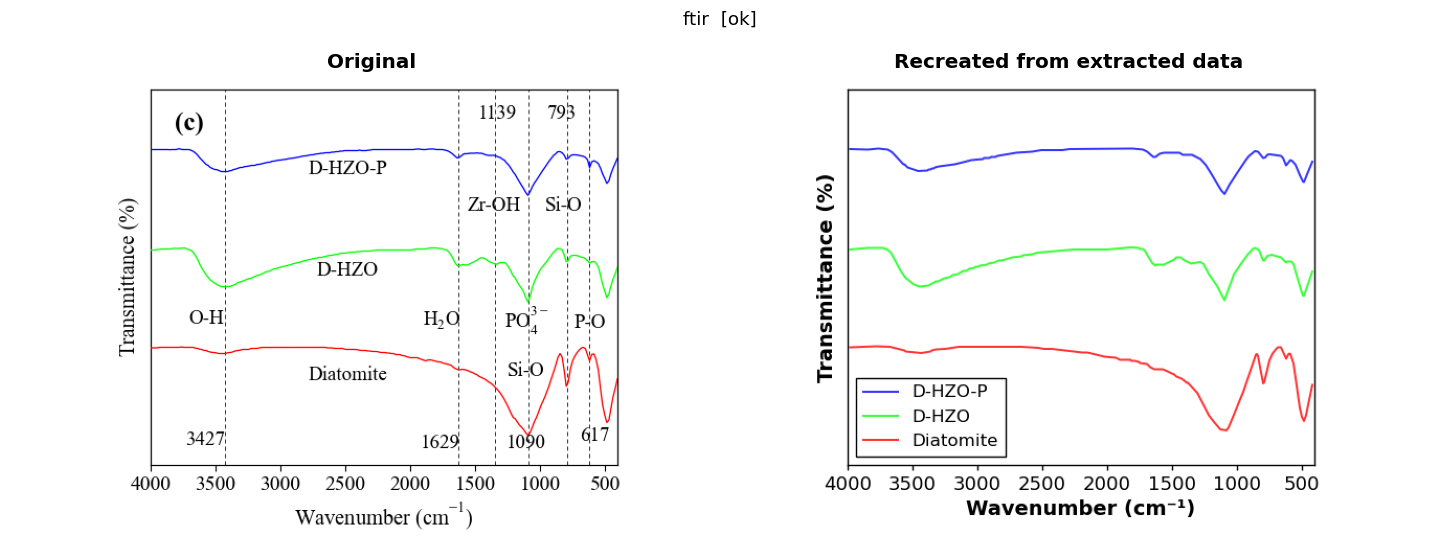

pore                 OK        type: None  rows: 30


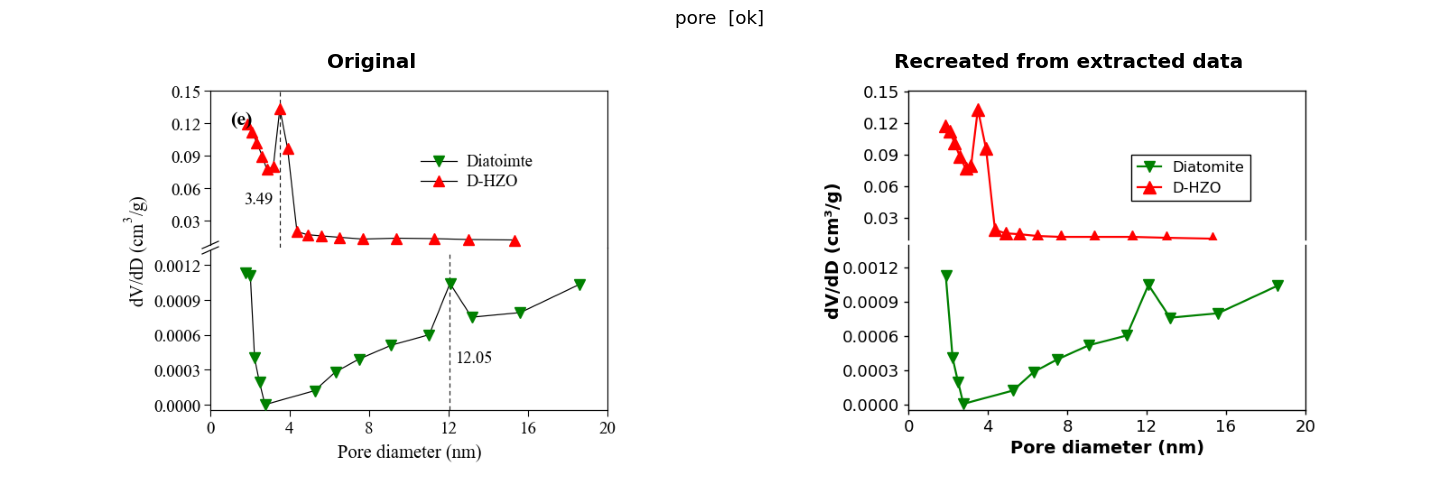

methane              OK        type: None  rows: 42
                      'CT': 5 marker(s) hidden under another series' markers recovered at the shared x positions
                      'RM': 2 marker(s) hidden under another series' markers recovered at the shared x positions


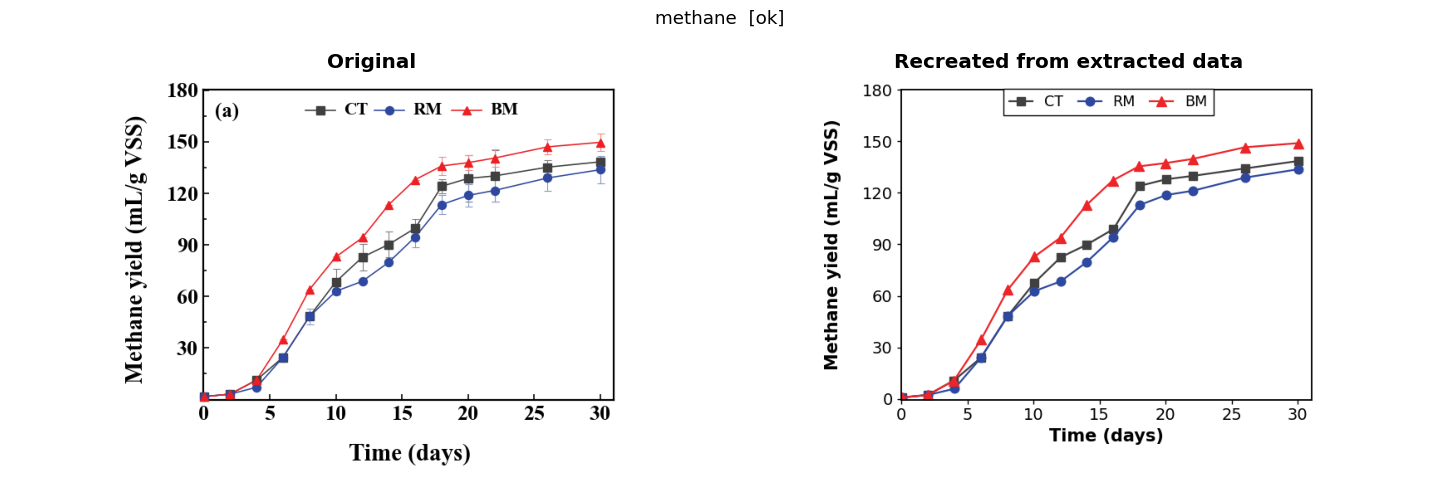

dosage               OK        type: None  rows: 31
                      'N removal efficiency': VLM said 'filled' markers, pixels show 'hollow' (47% of the marker is an enclosed hole) - pixels used
                      'P removal efficiency': VLM said 'filled' markers, pixels show 'hollow' (13% of the marker is an enclosed hole) - pixels used
                      'N adsorption capacity': 3 marker(s) hidden under another series' markers recovered at the shared x positions


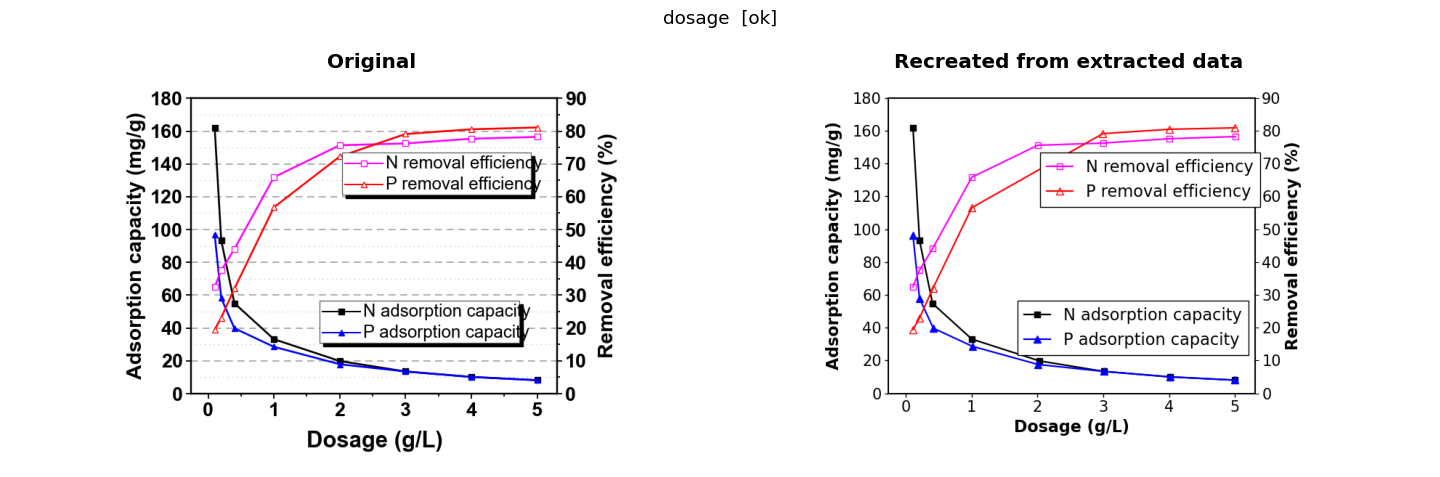

n2                   OK        type: None  rows: 50
                      'N2 uptaken (cm3/g) (lower)': VLM said line 'none', pixels show 'solid' (100% of the gaps between markers are inked) - pixels used
                      'N2 uptaken (cm3/g) (upper)': VLM said line 'none', pixels show 'solid' (100% of the gaps between markers are inked) - pixels used


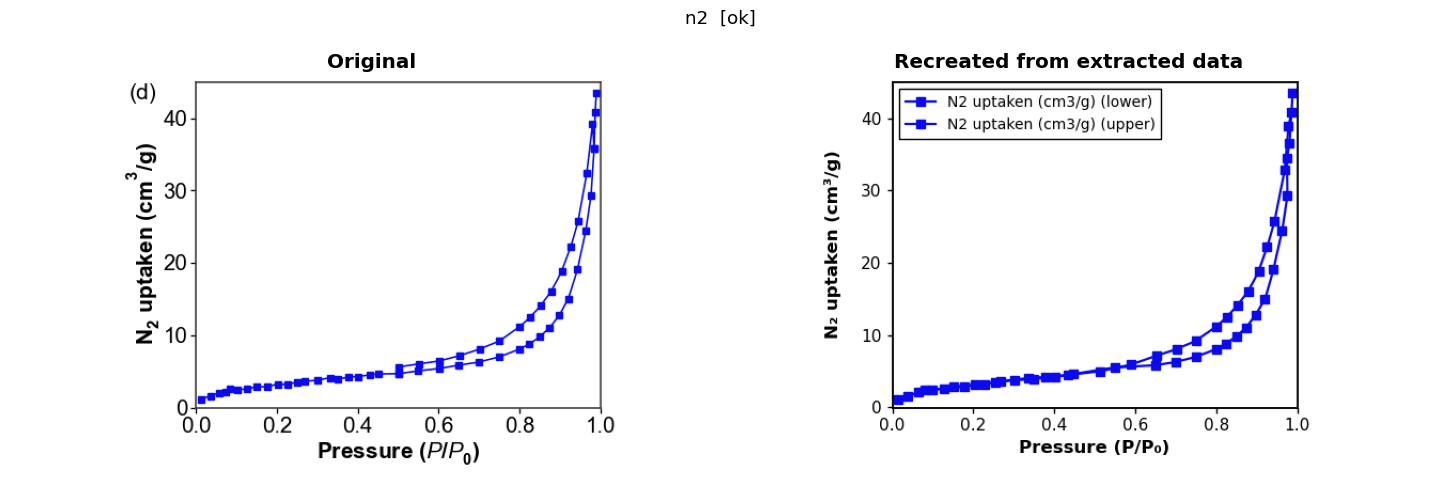

kinetics             OK        type: None  rows: 225


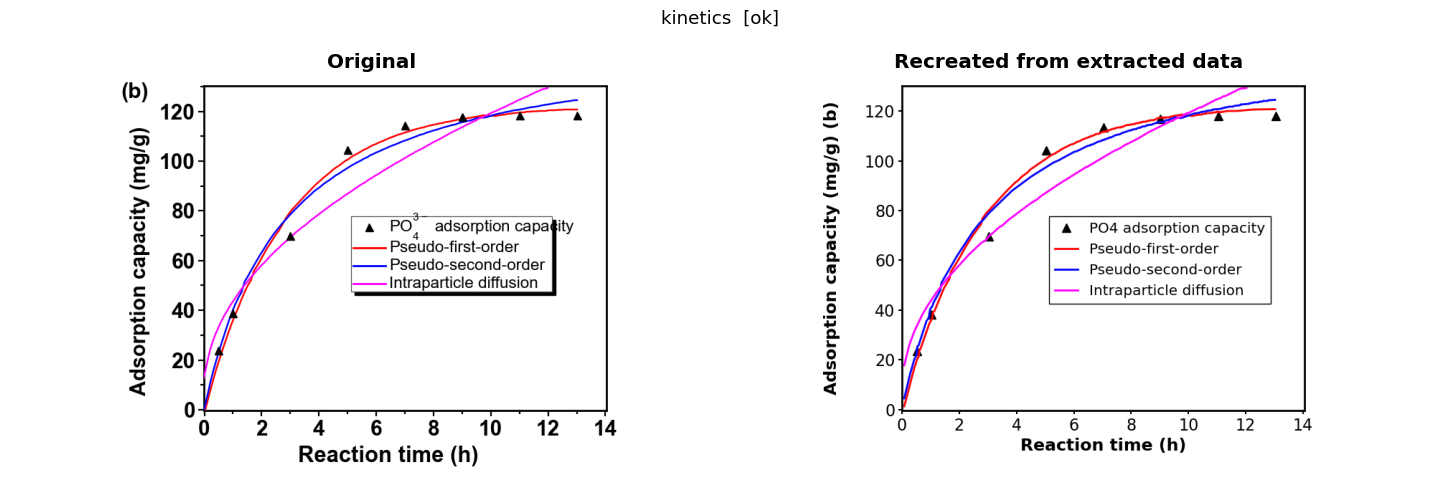

ph                   OK        type: bar  rows: 3


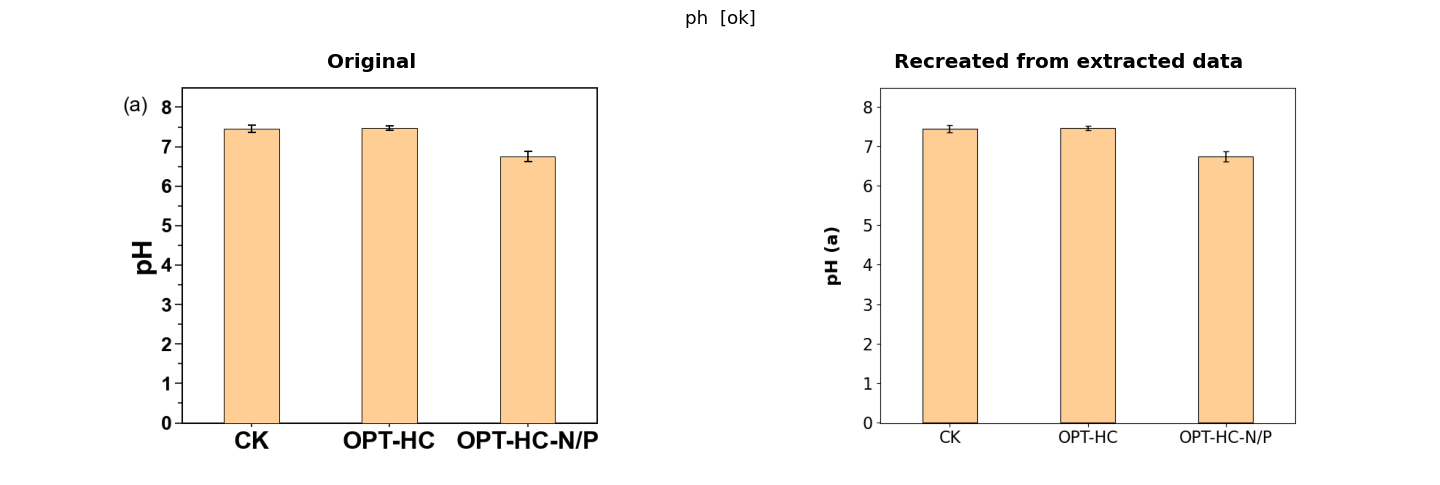

concentration        OK        type: bar  rows: 12


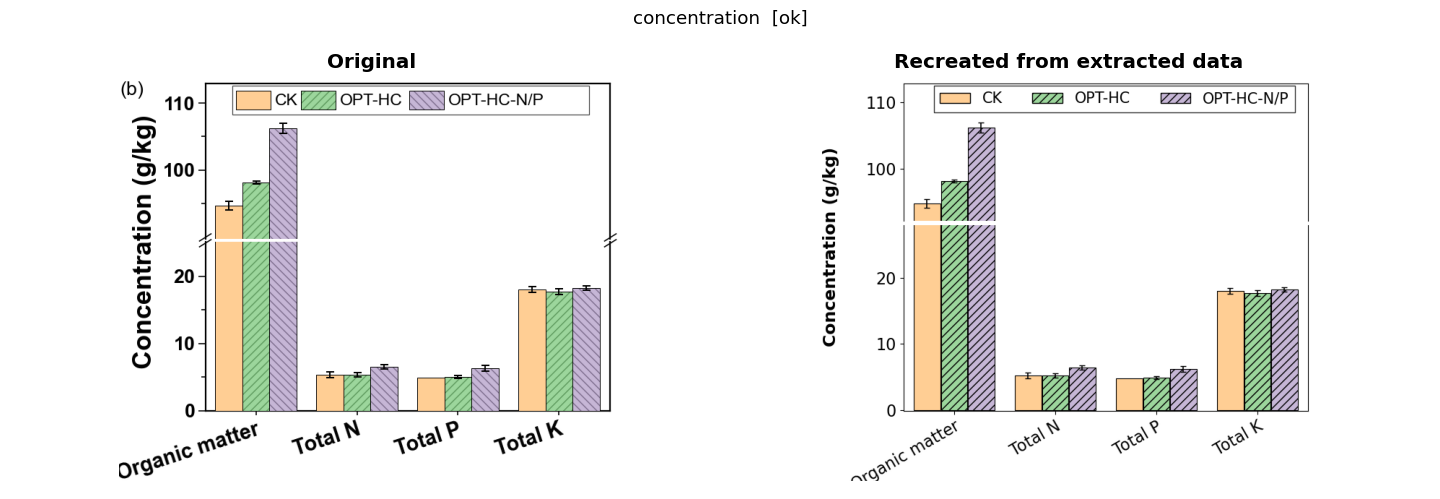

concentration2       OK        type: bar  rows: 12


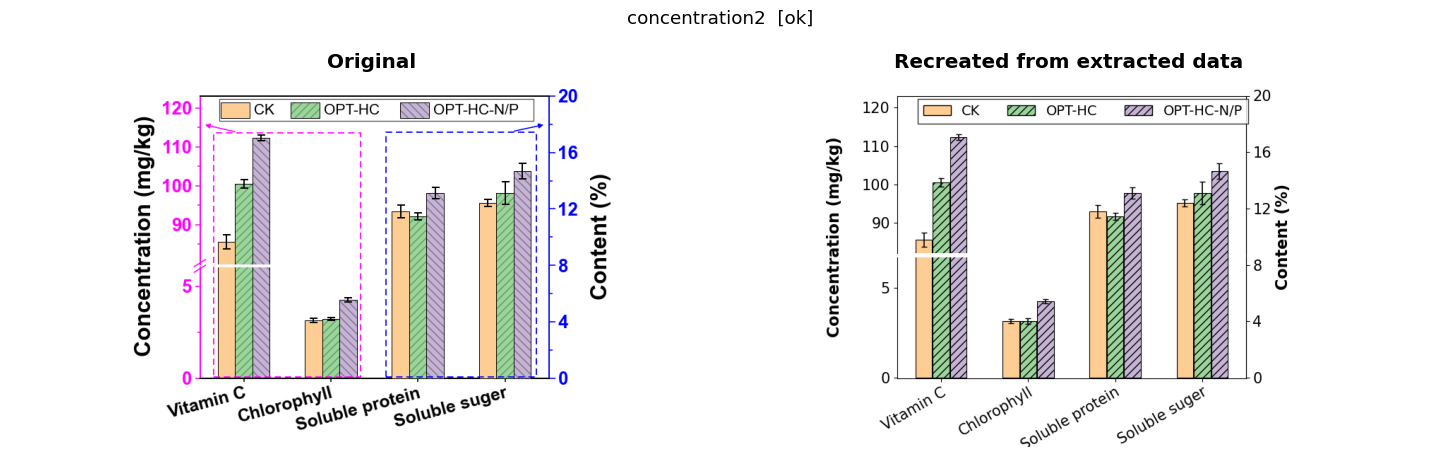

climet               OK        type: bar  rows: 36


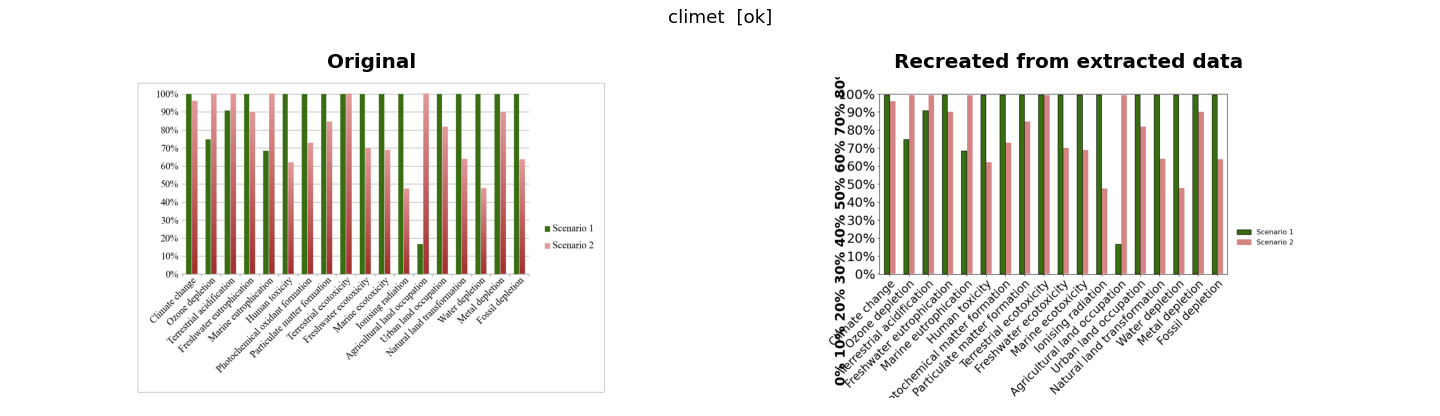

pie1                 OK        type: pie  rows: 4


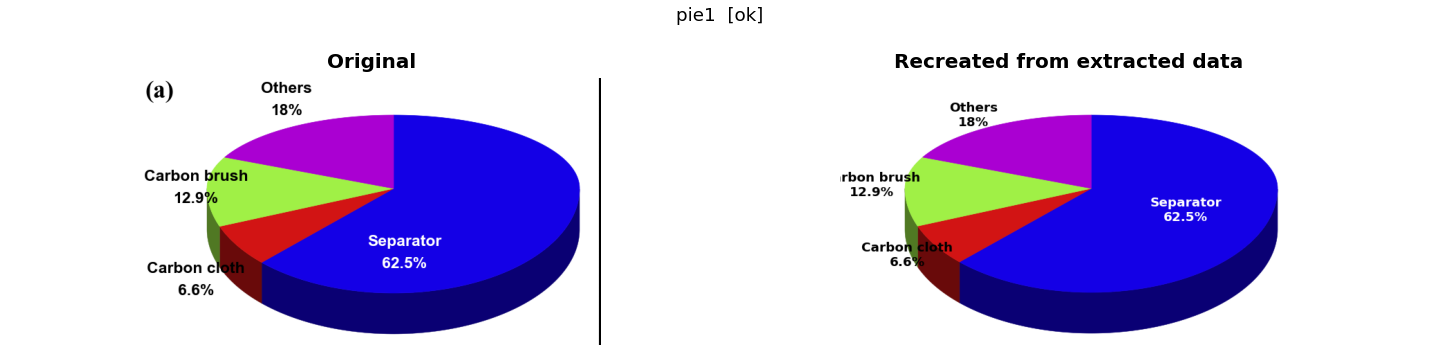

pie2                 OK        type: pie  rows: 4


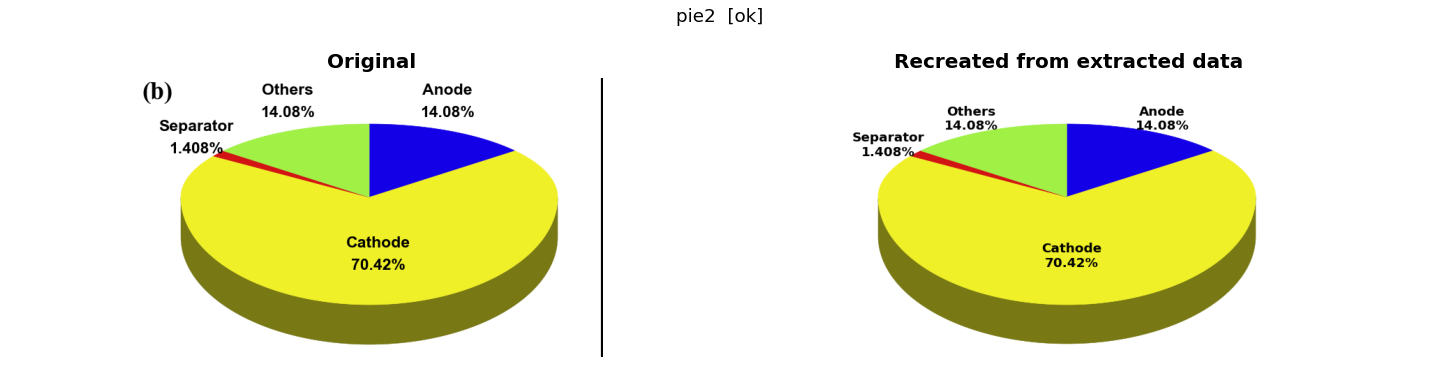

In [5]:
results, t_dig = {}, {}
for name, img in IMAGES.items():
    t = time.time()
    res = pipeline(img, specs[name])
    t_dig[name] = time.time() - t
    results[name] = res
    (OUT / name / "extraction.json").write_text(json.dumps(_jsonable(res), indent=1))
    csv_path = OUT / name / "extracted.csv"
    if csv_path.exists():
        csv_path.unlink()                      # a rejected image must not keep an old CSV
    E.write_csv(res, csv_path)
    rec = recreate(res, OUT / name / "recreated.png")
    side_by_side(img, rec, OUT / name / "side_by_side.png", f"{name}  [{res['status']}]")
    n_rows = len(res["table"]) if "table" in res else sum(len(d.get("x", [])) for d in res["series"].values())
    print(f"{name:20s} {res['status'].upper():9s} type: {res.get('chart_type')}  rows: {n_rows}")
    for r_ in res["status_reasons"]:
        print(f"{'':22s}{r_}")
    for w in res["warnings"]:
        print(f"{'':22s}{w}")
    display(IPImage(filename=str(OUT / name / "side_by_side.png"), width=950))

## 2b · Status of every image: ok / flagged / rejected, with the self-checks

In [6]:
status = pd.DataFrame([{"figure": n, "chart type (VLM)": specs[n].get("chart_type"), "status": r["status"],
                        "reason": "; ".join(r["status_reasons"])[:160],
                        "checks passed": f"{sum(1 for c in r['checks'] if c[3])}/{len(r['checks'])}"} for n, r in results.items()]).set_index("figure")
display(status.style.apply(lambda r: ["background-color: #fde2e2" if r["status"] == "rejected" else
                                      ("background-color: #fff3cd" if r["status"] == "flagged" else "") for _ in r], axis=1))
status.to_csv(OUT / "status.csv")
for n, r in results.items():
    if r["checks"]:
        print(n, " | ".join(f"{c[0]}: {c[1]} ({'ok' if c[3] else 'FAIL'})" for c in r["checks"]))

,chart type (VLM),status,reason,checks passed
figure,,,,
ftir,line,ok,,2/2
pore,line,ok,,3/3
methane,line,ok,,3/3
dosage,line,ok,,4/4
n2,scatter,ok,,3/3
kinetics,line,ok,,3/3
ph,bar,ok,,3/3
concentration,bar,ok,,3/3
concentration2,bar,ok,,4/4


ftir x axis label fit (px): 0.27 (ok) | data points extracted: 196 (ok)
pore x axis label fit (px): 0.15 (ok) | y axis label fit (px): 0.28 (ok) | data points extracted: 30 (ok)
methane x axis label fit (px): 0.22 (ok) | y axis label fit (px): 0.14 (ok) | data points extracted: 42 (ok)
dosage x axis label fit (px): 0.3 (ok) | y axis label fit (px): 0.3 (ok) | y axis right label fit (px): 0.3 (ok) | data points extracted: 31 (ok)
n2 x axis label fit (px): 0.43 (ok) | y axis label fit (px): 0.28 (ok) | data points extracted: 50 (ok)
kinetics x axis label fit (px): 0.41 (ok) | y axis label fit (px): 0.28 (ok) | data points extracted: 225 (ok)
ph y axis label fit (px): 0.26 (ok) | data points extracted: 3 (ok) | bars found / expected: 3/3 (ok)
concentration y axis label fit (px): 0.12 (ok) | data points extracted: 12 (ok) | bars found / expected: 12/12 (ok)
concentration2 y axis label fit (px): 0.0 (ok) | y axis right label fit (px): 0.26 (ok) | data points extracted: 12 (ok) | bars found 

## 3 · Ground truth vs extracted, point by point
For each plot: the ground truth placed on the image with the benchmark's own calibration (black circles — they sit on the markers, so the ground truth is right), the extracted points (orange ×) and the missed points (red circles); then one row per ground-truth point.
*error* = |y extracted − y truth| / span of that series' y-axis (for a broken axis: the span of its own segment; for a bar: the axis its category uses; for a pie: 100 %); *point accuracy* = 100 − error; *hit* = error ≤ 5 %. Traced curves are compared at 25 evenly spaced x; bars and slices are matched by category.

In [7]:
if SCORED:
    point_tables, summary = {}, []
    for fid, img in IMAGES.items():
        if results[fid]["status"] != "ok":
            print(f"{fid}: {results[fid]['status']} - not scored ({'; '.join(results[fid]['status_reasons'])[:120]})")
            continue
        mapping = E.match_names([n for n, d in results[fid]["series"].items() if d["x"]], list(GT[fid]["series"]))
        df = RP.point_table(fid, GT[fid], results[fid], mapping)
        point_tables[fid] = df
        df.to_csv(OUT / fid / "points_truth_vs_extracted.csv", index=False)
        from autodig.prf import prf_rebuilt
        pr = prf_rebuilt(fid, GT[fid], results[fid], mapping, CONFIG["hit_threshold"])
        summary.append(RP.summary_row(fid, df) | {k: pr[k] for k in ("precision %", "recall %", "F1 %", "extracted items")})
        RP.gt_on_image(fid, img, GT[fid], results[fid], FIGURES, df, OUT / fid / "truth_on_image.png"); plt.show()
        fmt = lambda v: v if isinstance(v, str) else f"{v:.4g}"
        display(df.style.format({"x": fmt, "y truth": "{:.4g}", "y extracted": "{:.4g}"}, na_rep="-")
                  .apply(lambda r: ["background-color: #fde2e2" if r["hit (<= 5 %)"] != "yes" else "" for _ in r], axis=1)
                  .hide(axis="index").set_caption(fid))
elif MODE == "gallery":
    gal_tables, gal_summary = {}, []
    for n in IMAGES:
        df = GE.score(GT[n], results[n], CONFIG["hit_threshold"])
        gal_tables[n] = df
        if len(df):
            df.to_csv(OUT / n / "points_truth_vs_extracted.csv", index=False)
        gal_summary.append(GE.summary(n, df, results[n]["status"], GT[n], results[n], CONFIG["hit_threshold"]) | {"truth type": GT[n].get("type")})
        if len(df) and results[n]["status"] != "rejected":
            worst = df.sort_values("error %", ascending=False).head(6)
            display(worst.style.format({"truth": "{:.4g}", "extracted": "{:.4g}"}, na_rep="-").hide(axis="index")
                    .set_caption(f"{n} [{results[n]['status']}] - 6 worst of {len(df)} items"))
else:
    print("no ground truth for these images")

series,extracted as,x,y truth,y extracted,error % of y-span,point accuracy %,hit (<= 5 %)
D-HZO-P,D-HZO-P,500,76.17,75.95,0.210000,99.790000,yes
D-HZO-P,D-HZO-P,645.8,81.76,81.72,0.050000,99.950000,yes
D-HZO-P,D-HZO-P,791.7,81.54,81.82,0.280000,99.720000,yes
D-HZO-P,D-HZO-P,937.5,80.51,80.99,0.480000,99.520000,yes
D-HZO-P,D-HZO-P,1083,72.37,73.06,0.690000,99.310000,yes
D-HZO-P,D-HZO-P,1229,79.26,79.2,0.060000,99.940000,yes
D-HZO-P,D-HZO-P,1375,82.45,82.59,0.140000,99.860000,yes
D-HZO-P,D-HZO-P,1521,83.01,83.15,0.140000,99.860000,yes
D-HZO-P,D-HZO-P,1667,82.64,82.66,0.020000,99.980000,yes
D-HZO-P,D-HZO-P,1812,84.1,84.26,0.160000,99.840000,yes


series,extracted as,x,y truth,y extracted,error % of y-span,point accuracy %,hit (<= 5 %)
Diatomite,Diatomite,1.761,0.00113,0.001128,0.150000,99.850000,yes
Diatomite,Diatomite,2.012,0.00111,0.0008357,19.680000,80.320000,no
Diatomite,Diatomite,2.227,0.0004,0.0004011,0.080000,99.920000,yes
Diatomite,Diatomite,2.477,0.00019,0.0002096,1.410000,98.590000,yes
Diatomite,Diatomite,2.75,0,1.554e-05,1.110000,98.890000,yes
Diatomite,Diatomite,5.25,0.00012,0.0001233,0.240000,99.760000,yes
Diatomite,Diatomite,6.295,0.00028,0.0002842,0.300000,99.700000,yes
Diatomite,Diatomite,7.477,0.00039,0.0003936,0.260000,99.740000,yes
Diatomite,Diatomite,9.114,0.00051,0.0005205,0.750000,99.250000,yes
Diatomite,Diatomite,11.02,0.0006,0.0006132,0.950000,99.050000,yes


series,extracted as,x,y truth,y extracted,error % of y-span,point accuracy %,hit (<= 5 %)
CT,CT,0,1.691,0.8055,0.490000,99.510000,yes
CT,CT,2,3.14,2.25,0.490000,99.510000,yes
CT,CT,4,11.35,10.79,0.310000,99.690000,yes
CT,CT,6,24.64,23.81,0.460000,99.540000,yes
CT,CT,8,48.31,47.67,0.350000,99.650000,yes
CT,CT,10,68.6,67,0.890000,99.110000,yes
CT,CT,12,82.85,82.01,0.470000,99.530000,yes
CT,CT,14,90.34,89.69,0.360000,99.640000,yes
CT,CT,16,99.76,98.67,0.600000,99.400000,yes
CT,CT,18,124.2,123.6,0.300000,99.700000,yes


series,extracted as,x,y truth,y extracted,error % of y-span,point accuracy %,hit (<= 5 %)
N adsorption capacity,N adsorption capacity,0.1,162.2,161.8,0.210000,99.790000,yes
N adsorption capacity,N adsorption capacity,0.2,93.39,98.67,2.930000,97.070000,yes
N adsorption capacity,N adsorption capacity,0.4,55.1,55.99,0.490000,99.510000,yes
N adsorption capacity,N adsorption capacity,1,33.2,33.12,0.040000,99.960000,yes
N adsorption capacity,N adsorption capacity,2,19.89,20.13,0.130000,99.870000,yes
N adsorption capacity,N adsorption capacity,3,13.5,13.37,0.070000,99.930000,yes
N adsorption capacity,N adsorption capacity,4,10.18,10.05,0.070000,99.930000,yes
N adsorption capacity,N adsorption capacity,5,8.188,8.02,0.090000,99.910000,yes
P adsorption capacity,P adsorption capacity,0.1,97.15,96.33,0.460000,99.540000,yes
P adsorption capacity,P adsorption capacity,0.2,58.2,60.87,1.480000,98.520000,yes


series,extracted as,x,y truth,y extracted,error % of y-span,point accuracy %,hit (<= 5 %)
adsorption,N2 uptaken (cm3/g) (lower),0.0124,1.107,1.065,0.090000,99.910000,yes
adsorption,N2 uptaken (cm3/g) (lower),0.0349,1.624,1.463,0.360000,99.640000,yes
adsorption,N2 uptaken (cm3/g) (lower),0.0568,1.961,1.883,0.170000,99.830000,yes
adsorption,N2 uptaken (cm3/g) (lower),0.0719,2.144,2.109,0.080000,99.920000,yes
adsorption,N2 uptaken (cm3/g) (lower),0.0829,2.54,2.228,0.690000,99.310000,yes
adsorption,N2 uptaken (cm3/g) (lower),0.101,2.435,2.417,0.040000,99.960000,yes
adsorption,N2 uptaken (cm3/g) (lower),0.1261,2.583,2.629,0.100000,99.900000,yes
adsorption,N2 uptaken (cm3/g) (lower),0.1499,2.878,2.829,0.110000,99.890000,yes
adsorption,N2 uptaken (cm3/g) (lower),0.1763,2.878,2.981,0.230000,99.770000,yes
adsorption,N2 uptaken (cm3/g) (lower),0.2014,3.247,3.122,0.280000,99.720000,yes


series,extracted as,x,y truth,y extracted,error % of y-span,point accuracy %,hit (<= 5 %)
PO4 adsorption capacity,PO4 adsorption capacity,0.5,23.93,23.36,0.440000,99.560000,yes
PO4 adsorption capacity,PO4 adsorption capacity,1,38.9,37.6,1.000000,99.000000,yes
PO4 adsorption capacity,PO4 adsorption capacity,3,70.01,69.1,0.700000,99.300000,yes
PO4 adsorption capacity,PO4 adsorption capacity,5,104.6,103.6,0.760000,99.240000,yes
PO4 adsorption capacity,PO4 adsorption capacity,7,114.4,113.4,0.780000,99.220000,yes
PO4 adsorption capacity,PO4 adsorption capacity,9,117.7,117,0.540000,99.460000,yes
PO4 adsorption capacity,PO4 adsorption capacity,11,118.4,118.2,0.200000,99.800000,yes
PO4 adsorption capacity,PO4 adsorption capacity,13,118.4,117.9,0.400000,99.600000,yes
Pseudo-first-order,Pseudo-first-order,0,-1.513,1.307,2.160000,97.840000,yes
Pseudo-first-order,Pseudo-first-order,0.5417,20.74,20.38,0.280000,99.720000,yes


... (2 outputs left out)

series,extracted as,x,y truth,y extracted,error % of y-span,point accuracy %,hit (<= 5 %)
CK,CK,Vitamin C,85.55,85.55,0.000000,100.000000,yes
CK,CK,Chlorophyll,3.135,3.127,0.120000,99.880000,yes
CK,CK,Soluble protein,11.82,11.79,0.150000,99.850000,yes
CK,CK,Soluble sugar,12.42,12.39,0.160000,99.840000,yes
OPT-HC,OPT-HC,Vitamin C,100.5,100.5,0.000000,100.000000,yes
OPT-HC,OPT-HC,Chlorophyll,3.212,3.143,1.130000,98.870000,yes
OPT-HC,OPT-HC,Soluble protein,11.47,11.44,0.150000,99.850000,yes
OPT-HC,OPT-HC,Soluble sugar,13.12,13.09,0.160000,99.840000,yes
OPT-HC-N/P,OPT-HC-N/P,Vitamin C,112.3,112.3,0.000000,100.000000,yes
OPT-HC-N/P,OPT-HC-N/P,Chlorophyll,4.25,4.247,0.050000,99.950000,yes


series,extracted as,x,y truth,y extracted,error % of y-span,point accuracy %,hit (<= 5 %)
Scenario 1,Scenario 1,Climate change,99.88,99.64,0.250000,99.750000,yes
Scenario 1,Scenario 1,Ozone depletion,74.71,74.7,0.010000,99.990000,yes
Scenario 1,Scenario 1,Terrestrial acidification,90.71,90.7,0.010000,99.990000,yes
Scenario 1,Scenario 1,Freshwater eutrophication,99.88,99.64,0.250000,99.750000,yes
Scenario 1,Scenario 1,Marine eutrophication,68.35,68.34,0.010000,99.990000,yes
Scenario 1,Scenario 1,Human toxicity,99.88,99.64,0.250000,99.750000,yes
Scenario 1,Scenario 1,Photochemical oxidant formation,99.88,99.64,0.250000,99.750000,yes
Scenario 1,Scenario 1,Particulate matter formation,99.88,99.64,0.250000,99.750000,yes
Scenario 1,Scenario 1,Terrestrial ecotoxicity,99.88,99.64,0.250000,99.750000,yes
Scenario 1,Scenario 1,Freshwater ecotoxicity,99.88,99.64,0.250000,99.750000,yes


series,extracted as,x,y truth,y extracted,error % of y-span,point accuracy %,hit (<= 5 %)
share (%),share (%),Separator,62.5,62.5,0.000000,100.000000,yes
share (%),share (%),Carbon cloth,6.6,6.6,0.000000,100.000000,yes
share (%),share (%),Carbon brush,12.9,12.9,0.000000,100.000000,yes
share (%),share (%),Others,18,18,0.000000,100.000000,yes


series,extracted as,x,y truth,y extracted,error % of y-span,point accuracy %,hit (<= 5 %)
share (%),share (%),Anode,14.08,14.08,0.000000,100.000000,yes
share (%),share (%),Cathode,70.42,70.42,0.000000,100.000000,yes
share (%),share (%),Separator,1.408,1.408,0.000000,100.000000,yes
share (%),share (%),Others,14.08,14.08,0.000000,100.000000,yes


## 4 · Overall per plot
**Precision / recall / F1** (`autodig/prf.py`) next to the hit rate. *Recall* = true items recovered within 5 % of the axis span; *precision* = extracted items that are within 5 % of a true item (invented points, split bars, an extra series count against it); *F1* = their harmonic mean. Markers are paired one-to-one (Hungarian; x must also agree within half the marker spacing), bars / slices / cells by category, traced curves / colour maps / surfaces sample-wise (each extracted sample against the true curve). Rejected and flagged plots are not in the means.

In [8]:
if SCORED:
    acc = pd.DataFrame(summary).set_index("figure")
    acc["VLM s"] = [spec_info[f].get("seconds") for f in acc.index]
    acc["digitize s"] = [round(t_dig[f], 2) for f in acc.index]
    acc.loc["MEAN"] = acc.mean(numeric_only=True).round(1)
    acc.loc["MEAN", "truth points"] = acc["truth points"][:-1].sum()
    acc.loc["MEAN", "missed points"] = acc["missed points"][:-1].sum()
    acc.loc["MEAN", "extracted items"] = acc["extracted items"][:-1].sum()
    print(f"mean precision {acc.loc['MEAN', 'precision %']} %   recall {acc.loc['MEAN', 'recall %']} %   F1 {acc.loc['MEAN', 'F1 %']} %")
    display(acc)
    acc.to_csv(OUT / "accuracy.csv")
    who = getattr(reader, "model_id", "hand-written spec (dry run)").split("/")[-1]
    mine = {"model": "vlm+digitizer", "label": f"{who} reads text + pixel digitizer (notebook 03)",
            "hit_rate_rebuilt": acc.loc["MEAN", "hit rate %"], "accuracy_rebuilt": acc.loc["MEAN", "accuracy %"],
            "coverage_rebuilt": acc.loc["MEAN", "coverage %"],
            "precision_rebuilt": acc.loc["MEAN", "precision %"], "recall_rebuilt": acc.loc["MEAN", "recall %"],
            "f1_rebuilt": acc.loc["MEAN", "F1 %"],
            "sec_per_image_rebuilt": (acc.loc["MEAN", "VLM s"] or 0) + acc.loc["MEAN", "digitize s"], "figures_rebuilt": len(IMAGES)}
    lb = RP.leaderboard_with(BENCH, mine)
    lb.to_csv(OUT / "leaderboard.csv", index=False)
    RP.leaderboard_chart(lb, OUT / "leaderboard.png", rebuilt_only=True); plt.show()
    print("saved:", OUT / "accuracy.csv", ",", OUT / "leaderboard.csv", "and <figure>/points_truth_vs_extracted.csv")

mean precision 98.1 %   recall 96.6 %   F1 97.3 %


,truth points,hit rate %,accuracy %,coverage %,mean error % (found points),missed points,precision %,recall %,F1 %,extracted items,VLM s,digitize s
figure,,,,,,,,,,,,
ftir,75.0,100.0,99.8,100.0,0.20,0.0,100.0,96.0,98.0,196.0,40.5,0.21
pore,31.0,96.8,98.6,100.0,1.43,1.0,100.0,96.8,98.4,30.0,41.2,0.19
methane,42.0,100.0,99.6,100.0,0.41,0.0,100.0,100.0,100.0,42.0,27.6,0.25
dosage,32.0,100.0,99.5,100.0,0.48,0.0,100.0,96.9,98.4,31.0,38.5,0.43
n2,53.0,96.2,99.3,100.0,0.66,2.0,78.0,73.6,75.7,50.0,23.7,0.13
kinetics,83.0,100.0,99.8,100.0,0.23,0.0,98.7,96.4,97.5,225.0,31.5,0.35
ph,3.0,100.0,99.9,100.0,0.10,0.0,100.0,100.0,100.0,3.0,25.8,0.17
concentration,12.0,100.0,99.9,100.0,0.09,0.0,100.0,100.0,100.0,12.0,32.6,0.20
concentration2,12.0,100.0,99.8,100.0,0.19,0.0,100.0,100.0,100.0,12.0,43.7,0.22


saved: outputs_qwen/accuracy.csv , outputs_qwen/leaderboard.csv and <figure>/points_truth_vs_extracted.csv


In [13]:
if MODE == "gallery":
    gs = pd.DataFrame(gal_summary).set_index("figure")
    display(gs)
    gs.to_csv(OUT / "gallery_accuracy.csv")
    ok = gs[(gs["status"] == "ok") & (gs["truth items"] > 0)]
    supported = gs[gs["truth type"] != "unsupported"]
    unknown = gs[gs["truth type"] == "unsupported"]
    print(f"supported plots: {len(supported)}  ok: {(supported.status == 'ok').sum()}  flagged: {(supported.status == 'flagged').sum()}  "
          f"rejected: {(supported.status == 'rejected').sum()}")
    print(f"mean over the {len(ok)} ok plots:  hit rate {ok['hit rate %'].mean():.1f} %   accuracy {ok['accuracy %'].mean():.1f} %   coverage {ok['coverage %'].mean():.1f} %")
    print(f"                           precision {ok['precision %'].mean():.1f} %   recall {ok['recall %'].mean():.1f} %   F1 {ok['F1 %'].mean():.1f} %")
    print(f"unsupported plots correctly rejected: {(unknown.status == 'rejected').sum()} / {len(unknown)}")
    print("per chart type (ok plots):")
    display(ok.groupby("truth type")[["precision %", "recall %", "F1 %", "hit rate %", "accuracy %", "coverage %"]].mean().round(1))

## 4b · Accuracy, precision, recall and F1 bar plots
Per-plot scores and their unweighted means. Gallery charts use only OK plots with ground truth, matching the summary above. Flagged and rejected gallery plots are excluded. Charts are displayed inline below.

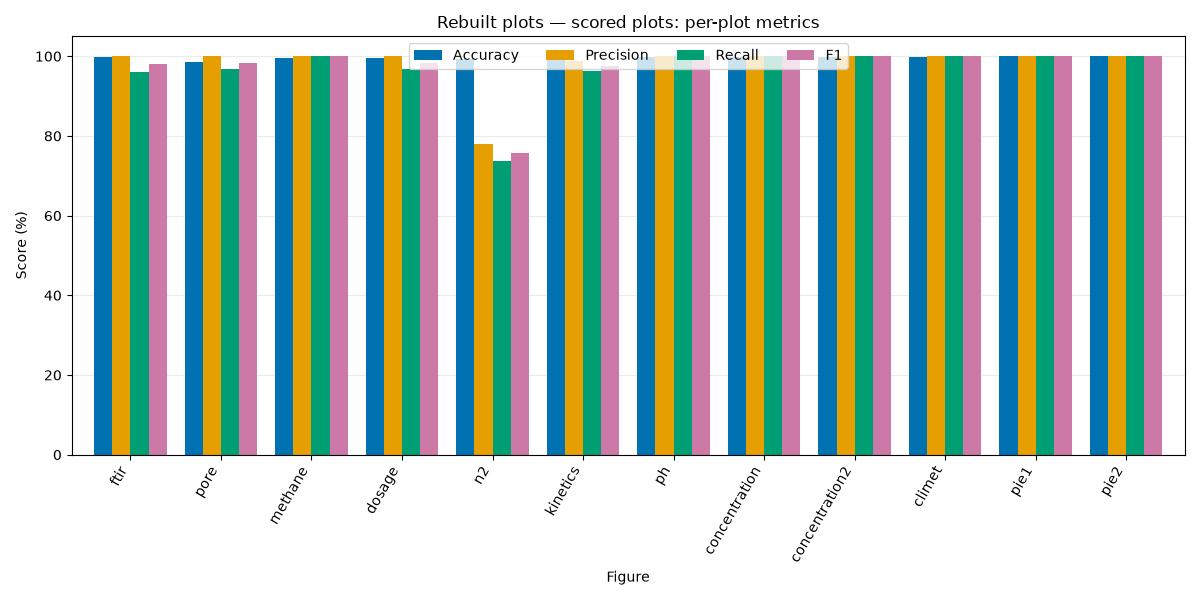

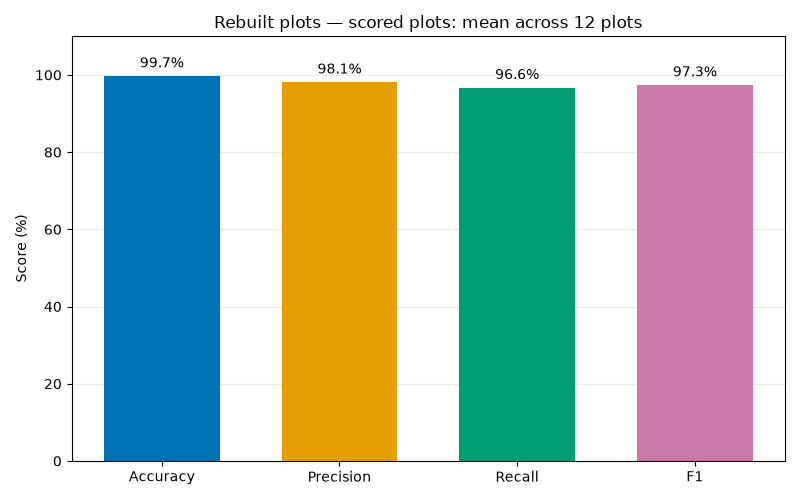

In [ ]:
# Accuracy, precision, recall and F1 bar plots (run after the summary cells).
metric_columns = ["accuracy %", "precision %", "recall %", "F1 %"]
metric_labels = ["Accuracy", "Precision", "Recall", "F1"]
metric_colors = ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]

if SCORED:
    metric_data = acc.drop(index="MEAN", errors="ignore").reindex(columns=metric_columns)
    metric_scope = "Rebuilt plots — scored plots"
elif MODE == "gallery":
    metric_data = gs.loc[(gs["status"] == "ok") & (gs["truth items"] > 0)].reindex(columns=metric_columns)
    metric_scope = "Gallery — OK plots with ground truth"
else:
    metric_data = pd.DataFrame(columns=metric_columns)
    metric_scope = "No ground truth"

metric_data = metric_data.apply(pd.to_numeric, errors="coerce").dropna(how="all")
if metric_data.empty:
    print("No scored plots available for accuracy, precision, recall and F1 charts.")
else:
    # Missing scores remain missing; means give each scored plot equal weight.
    metric_plot_data = metric_data.rename(columns=dict(zip(metric_columns, metric_labels)))
    fig, ax = plt.subplots(figsize=(max(12, 0.7 * len(metric_data)), 6))
    metric_plot_data.plot.bar(ax=ax, color=metric_colors, width=0.8)
    ax.set(title=f"{metric_scope}: per-plot metrics", xlabel="Figure", ylabel="Score (%)", ylim=(0, 105))
    ax.tick_params(axis="x", labelrotation=60)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment("right")
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(title=None, ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.0))
    fig.tight_layout()
    plt.show()
    plt.close(fig)

    metric_means = metric_plot_data.mean()
    fig, ax = plt.subplots(figsize=(8, 5))
    bars = ax.bar(metric_labels, metric_means, color=metric_colors, width=0.65)
    ax.bar_label(bars, labels=[f"{v:.1f}%" if pd.notna(v) else "N/A" for v in metric_means], padding=4)
    ax.set(title=f"{metric_scope}: mean across {len(metric_data)} plots", ylabel="Score (%)", ylim=(0, 110))
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    plt.show()
    plt.close(fig)


In [10]:
# free the GPU / MPS memory (Qwen) / API usage (OpenAI)
if hasattr(reader, "usage"):
    print("OpenAI calls:", reader.usage["calls"], " input tokens:", reader.usage["input_tokens"], " output tokens:", reader.usage["output_tokens"])
if hasattr(reader, "unload"):
    reader.unload()